# 01. 원료 데이터 전처리와 EDA

**목표:** 원본 → 중복·범위 정제 → 개발/예약 분리 → 학습 구간 보간 → 17개 특성 → 표준화의 흐름을 실제 표와 그림으로 확인합니다.

영풍 제공 원본만 사용합니다. 첫 357개 배치는 개발용이며 마지막 63개는 이번 학습·튜닝·성능 평가에서 제외합니다. 63개는 과거 확인 이력이 있는 예약 구간이므로 새 blind test가 아닙니다. 이 노트북에서 개발 전체로 만든 보간·표준화 자료는 설명용이며, 교차검증은 각 학습 fold에서 통계를 따로 구합니다.

모델 의존성은 `module2_prediction/requirements.txt`에 있습니다. [노트북 실행 안내](README.md)와 [모듈 1 전처리 규칙](../module1_preprocessing/README.md)을 참고하세요.

In [1]:
from pathlib import Path
import sys
import json
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

# 저장소 내부의 어디에서 열어도 루트를 찾습니다. 개인·절대 경로는 사용하지 않습니다.
start = Path.cwd().resolve()
ROOT = next((p for p in (start, *start.parents)
             if (p / "module1_preprocessing").is_dir()
             and (p / "module2_prediction").is_dir()
             and (p / "module3_optimization").is_dir()), None)
if ROOT is None:
    raise RuntimeError("저장소 전체를 가져온 뒤 저장소 루트 또는 notebooks 폴더에서 실행하세요.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
get_ipython().run_line_magic("matplotlib", "inline")
pd.set_option("display.max_columns", 24)
pd.set_option("display.precision", 6)
print({"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__})

{'python': '3.12.14', 'numpy': '2.3.5', 'pandas': '2.2.3'}


## 1. 전처리 실행과 행 수 확인

`run_preprocessing()`으로 모듈의 실제 처리를 수행하고 생성된 파일을 읽습니다. 원자료는 보존되며 정제 결과는 별도 폴더에 저장됩니다. 등급은 보간에 쓰는 보조 정보이고 최종 추론 입력은 숫자 11개입니다.

In [2]:
from module1_preprocessing.pipeline import load_raw_data, load_clean_data, run_preprocessing, FoldPreprocessor
from module1_preprocessing.schema import BASE, CHEM, TARGETS, LIMITS, PLOT_LABELS
from module1_preprocessing.features import feature_names

preprocessing = run_preprocessing()
OUT = Path(preprocessing["output_dir"])
audit = preprocessing["audit"]
raw = load_raw_data()
clean = load_clean_data()
dev = pd.read_csv(OUT / "development357.csv")
reserved = pd.read_csv(OUT / "holdout63.csv")
display(pd.Series(audit["rows"], name="rows").to_frame())
assert (len(raw), len(clean), len(dev), len(reserved)) == (424, 420, 357, 63)
display(raw.head(5))
display(clean.head(5))

,rows
raw,424
duplicates_removed,4
cleaned,420
development,357
holdout,63
development_complete_observed,151


,배치ID,분석일자,원료등급,Ni_함량_pct,Co_함량_pct,Li_함량_pct,Mn_함량_pct,Cu_불순물_pct,Fe_불순물_pct,Al_불순물_pct,원료투입량_kg,황산투입량_L,침출온도_C,침출시간_hr,Ni_회수율_pct,Co_회수율_pct
0,BP-2025-0001,2025-01-02,C,13.30,NaN,2.93,13.66,1.71,NaN,2.87,121.1,1107,88.8,1.33,85.87,77.34
1,BP-2025-0002,2025/01/02,B,12.17,6.98,4.25,10.49,1.90,2.04,3.43,159.1,1118,55.6,6.32,85.65,78.45
2,BP-2025-0003,03.01.2025,C,11.83,6.76,3.06,10.33,2.97,1.87,3.52,128.3,1069,84.9,NaN,87.40,79.18
3,BP-2025-0004,20250103,B,17.10,9.21,4.83,8.51,2.00,0.98,2.83,98.5,1455,77.7,7.98,98.79,88.33
4,BP-2025-0005,"Jan 03, 2025",A급,23.67,NaN,5.06,8.09,0.64,NaN,0.94,143.4,959,68.2,3.44,87.06,83.92


,배치ID,분석일자,원료등급,Ni_함량_pct,Co_함량_pct,Li_함량_pct,Mn_함량_pct,Cu_불순물_pct,Fe_불순물_pct,Al_불순물_pct,원료투입량_kg,황산투입량_L,침출온도_C,침출시간_hr,Ni_회수율_pct,Co_회수율_pct
0,BP-2025-0001,2025-01-02,C,13.30,NaN,2.93,13.66,1.71,NaN,2.87,121.1,1107.0,88.8,1.33,85.87,77.34
1,BP-2025-0002,2025/01/02,B,12.17,6.98,4.25,10.49,1.90,2.04,3.43,159.1,1118.0,55.6,6.32,85.65,78.45
2,BP-2025-0003,03.01.2025,C,11.83,6.76,3.06,10.33,2.97,1.87,3.52,128.3,1069.0,84.9,NaN,87.40,79.18
3,BP-2025-0004,20250103,B,17.10,9.21,4.83,8.51,2.00,0.98,2.83,98.5,1455.0,77.7,7.98,98.79,88.33
4,BP-2025-0005,"Jan 03, 2025",A,23.67,NaN,5.06,8.09,0.64,NaN,0.94,143.4,959.0,68.2,3.44,87.06,83.92


## 2. 결측과 범위 밖 값은 구분해서 기록

범위 위반값은 결측으로 전환하고 원자료에서 원래 값을 추적합니다. 999 같은 값도 허용 범위 경계에 붙이지 않습니다. 다음 표는 원본 결측, 숫자 변환 실패, 범위 밖 추가 결측, 개발·예약 구간의 결측 수를 구분합니다.

개발 구간 보간 대상 셀 수: 303


,feature,unit,source_empty_after_dedup,numeric_coercion_to_missing,out_of_range_to_missing,cleaned_missing,development_missing,holdout_missing
0,Ni_함량_pct,wt%,30,0,11,41,35,6
1,Co_함량_pct,wt%,31,0,0,31,27,4
2,Li_함량_pct,wt%,33,0,5,38,36,2
3,Mn_함량_pct,wt%,25,0,4,29,25,4
4,Cu_불순물_pct,wt%,28,0,14,42,35,7
5,Fe_불순물_pct,wt%,35,0,10,45,39,6
6,Al_불순물_pct,wt%,26,0,13,39,35,4
7,원료투입량_kg,kg,0,0,0,0,0,0
8,황산투입량_L,L,0,0,2,2,2,0
9,침출온도_C,deg C,38,0,2,40,35,5


,missing_cells
cleaned,345
development,303
holdout,42


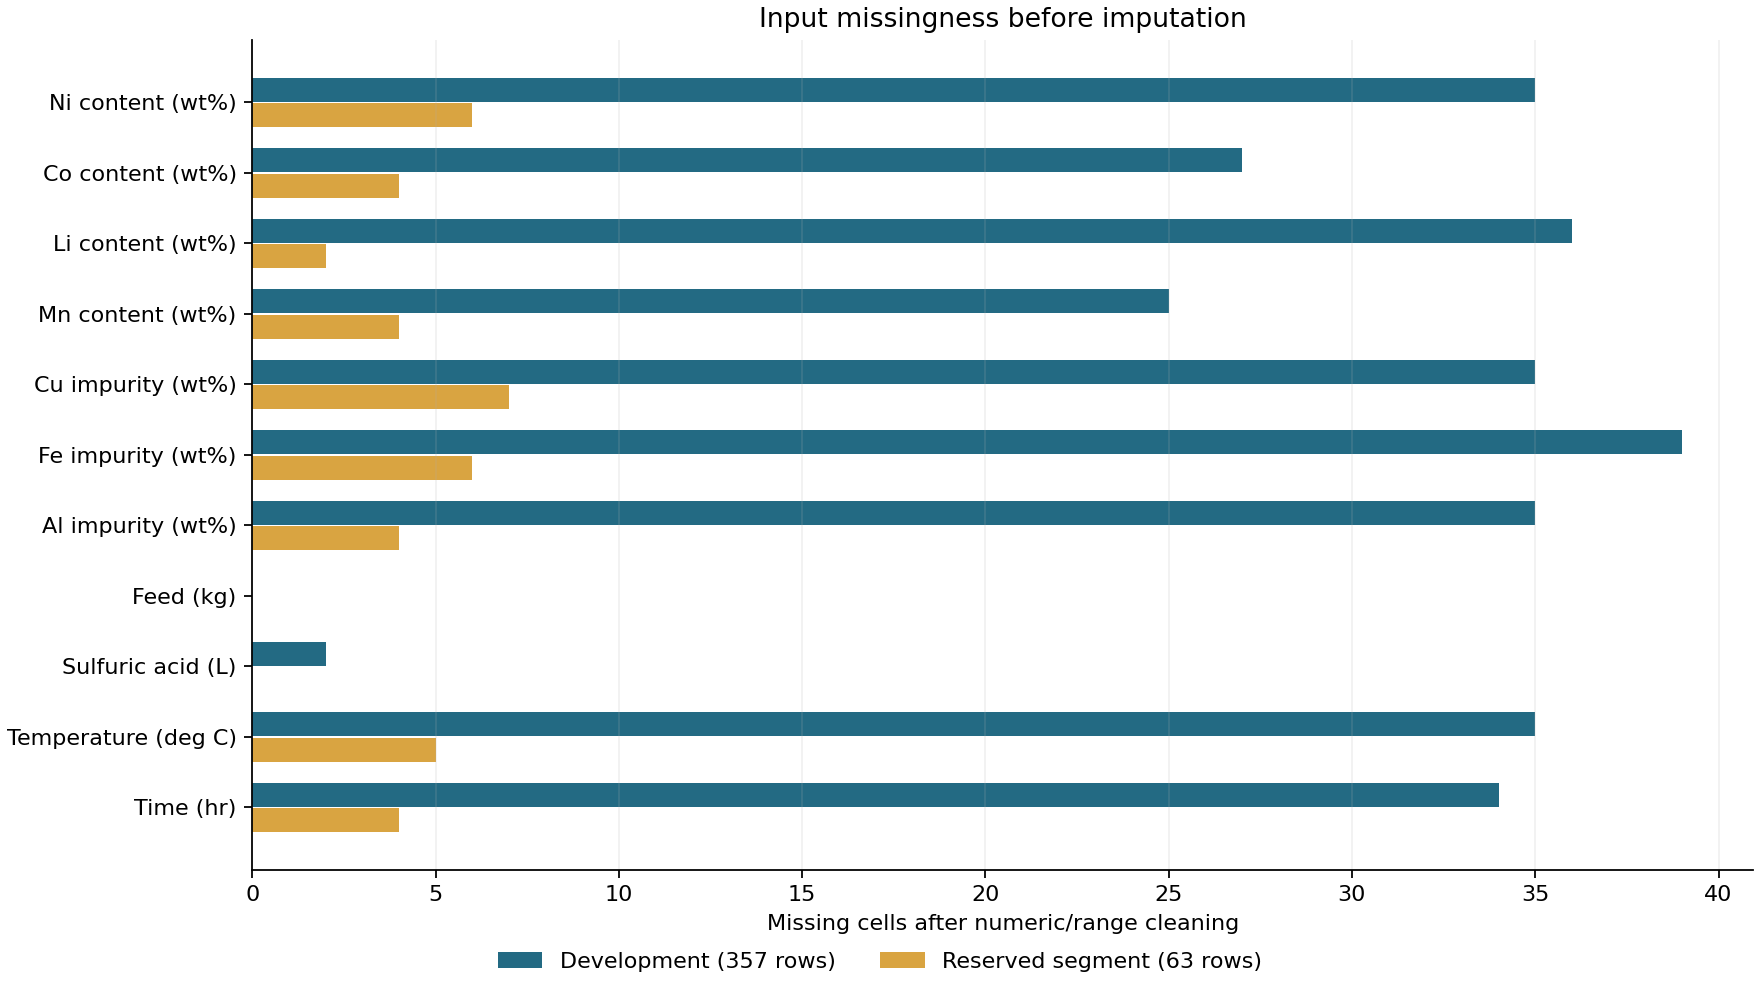

In [3]:
missing = pd.read_csv(OUT / "quality" / "missing_counts.csv")
display(missing[["feature", "unit", "source_empty_after_dedup", "numeric_coercion_to_missing",
                 "out_of_range_to_missing", "cleaned_missing", "development_missing", "holdout_missing"]])
display(pd.Series(audit["missing_input_cells"], name="missing_cells").to_frame())
print("개발 구간 보간 대상 셀 수:", audit["development_imputed_cells"])
display(Image(filename=str(OUT / "quality" / "missing_counts.png")))

In [4]:
# 보존된 원자료에서 실제 범위 위반값을 읽어 확인하는 진단 표입니다.
raw_unique = raw.drop_duplicates("배치ID", keep="first")
range_rows = []
for feature in BASE:
    numeric = pd.to_numeric(raw_unique[feature], errors="coerce")
    lo, hi = LIMITS[feature]
    bad = numeric.notna() & ~numeric.between(lo, hi)
    for index in raw_unique.index[bad]:
        range_rows.append({"batch": raw_unique.loc[index, "배치ID"], "feature": feature,
                           "raw_value": numeric.loc[index], "lower": lo, "upper": hi})
range_violations = pd.DataFrame(range_rows)
display(range_violations.head(15))
display(range_violations.groupby("feature").size().rename("range_violation_cells").to_frame())

,batch,feature,raw_value,lower,upper
0,BP-2025-0011,Ni_함량_pct,999.00,8.0,30
1,BP-2025-0025,Ni_함량_pct,999.00,8.0,30
2,BP-2025-0117,Ni_함량_pct,7.47,8.0,30
3,BP-2025-0202,Ni_함량_pct,7.07,8.0,30
4,BP-2025-0209,Ni_함량_pct,999.00,8.0,30
5,BP-2025-0219,Ni_함량_pct,7.70,8.0,30
6,BP-2025-0277,Ni_함량_pct,30.92,8.0,30
7,BP-2025-0281,Ni_함량_pct,30.33,8.0,30
8,BP-2025-0297,Ni_함량_pct,6.92,8.0,30
9,BP-2025-0327,Ni_함량_pct,7.61,8.0,30


,range_violation_cells
feature,
Al_불순물_pct,13
Cu_불순물_pct,14
Fe_불순물_pct,10
Li_함량_pct,5
Mn_함량_pct,4
Ni_함량_pct,11
침출시간_hr,2
침출온도_C,2
황산투입량_L,2


## 3. IQR 검토 후보와 결측 보간

개발 구간의 1.5×IQR 범위를 벗어나는 값은 검토 후보로 남깁니다. 이 후보를 이유로 행을 자동 삭제하지 않습니다. 데이터 사전 범위 위반과 IQR 검토 후보는 서로 다른 절차입니다.

보간은 성분 7개에 학습 등급별 중앙값을 사용하되 관측 수가 5개 미만이면 학습 전체 중앙값으로 대체합니다. 원료 투입량과 공정조건 3개는 학습 전체 중앙값을 사용하며, 정답은 보간하지 않습니다.

In [5]:
iqr_candidates = pd.read_csv(OUT / "quality" / "outlier_candidates.csv")
iqr_rules = pd.read_csv(OUT / "quality" / "outlier_rules.csv")
display(iqr_rules)
display(iqr_candidates)
print("IQR 후보 셀 / 삭제 행:", audit["iqr"]["candidate_cells"], "/", audit["iqr"]["rows_deleted"])
imputed = pd.read_csv(OUT / "development_imputed.csv")
imputer_state = json.loads((OUT / "imputer_state.json").read_text(encoding="utf-8"))
display(pd.DataFrame({"before": dev[list(BASE)].isna().sum(),
                      "after": imputed[list(BASE)].isna().sum()}))
display(pd.DataFrame(imputer_state["grade_count"]).T.rename_axis("grade"))
display(pd.DataFrame(imputer_state["grade_median"]).T.rename_axis("grade"))

IQR 후보 셀 / 삭제 행: 16 / 0


,feature,unit,observed_n,q1,q3,iqr,lower_fence,upper_fence
0,Ni_함량_pct,wt%,322,14.6475,23.0425,8.3950,2.05500,35.63500
1,Co_함량_pct,wt%,330,6.2100,10.4550,4.2450,-0.15750,16.82250
2,Li_함량_pct,wt%,321,3.2200,4.4400,1.2200,1.39000,6.27000
3,Mn_함량_pct,wt%,332,8.9400,11.6875,2.7475,4.81875,15.80875
4,Cu_불순물_pct,wt%,322,0.9525,2.4300,1.4775,-1.26375,4.64625
5,Fe_불순물_pct,wt%,318,0.7425,2.1900,1.4475,-1.42875,4.36125
6,Al_불순물_pct,wt%,322,1.3750,3.5075,2.1325,-1.82375,6.70625
7,원료투입량_kg,kg,357,114.4000,174.7000,60.3000,23.95000,265.15000
8,황산투입량_L,L,355,682.0000,1183.5000,501.5000,-70.25000,1935.75000
9,침출온도_C,deg C,322,53.1500,81.6000,28.4500,10.47500,124.27500


,batch_id,split,feature,unit,value,lower_fence,upper_fence,action
0,BP-2025-0006,development,Cu_불순물_pct,wt%,4.69,-1.26375,4.64625,retain_for_review
1,BP-2025-0025,development,Cu_불순물_pct,wt%,4.70,-1.26375,4.64625,retain_for_review
2,BP-2025-0101,development,Cu_불순물_pct,wt%,4.67,-1.26375,4.64625,retain_for_review
3,BP-2025-0151,development,Cu_불순물_pct,wt%,5.11,-1.26375,4.64625,retain_for_review
4,BP-2025-0297,development,Cu_불순물_pct,wt%,5.13,-1.26375,4.64625,retain_for_review
5,BP-2025-0325,development,Cu_불순물_pct,wt%,4.91,-1.26375,4.64625,retain_for_review
6,BP-2025-0014,development,Fe_불순물_pct,wt%,4.43,-1.42875,4.36125,retain_for_review
7,BP-2025-0219,development,Fe_불순물_pct,wt%,4.64,-1.42875,4.36125,retain_for_review
8,BP-2025-0252,development,Fe_불순물_pct,wt%,5.73,-1.42875,4.36125,retain_for_review
9,BP-2025-0295,development,Fe_불순물_pct,wt%,4.39,-1.42875,4.36125,retain_for_review


,before,after
Ni_함량_pct,35,0
Co_함량_pct,27,0
Li_함량_pct,36,0
Mn_함량_pct,25,0
Cu_불순물_pct,35,0
Fe_불순물_pct,39,0
Al_불순물_pct,35,0
원료투입량_kg,0,0
황산투입량_L,2,0
침출온도_C,35,0


,Ni_함량_pct,Co_함량_pct,Li_함량_pct,Mn_함량_pct,Cu_불순물_pct,Fe_불순물_pct,Al_불순물_pct
grade,,,,,,,
A,114,121,118,123,107,110,112
B,132,129,127,128,133,129,128
C,76,80,76,81,82,79,82


,Ni_함량_pct,Co_함량_pct,Li_함량_pct,Mn_함량_pct,Cu_불순물_pct,Fe_불순물_pct,Al_불순물_pct
grade,,,,,,,
A,24.225,10.99,4.575,8.980,0.76,0.635,1.235
B,18.285,7.72,3.790,10.905,1.82,1.530,2.610
C,12.370,5.01,2.955,12.000,3.44,3.160,4.465


In [6]:
# 실제 첫 바깥 학습 fold(90행)와 전체 개발(357행)의 통계를 비교합니다.
# 검증에서는 반드시 해당 학습 fold의 값을 사용합니다.
first_fold_preprocessor = FoldPreprocessor("A17").fit(dev.iloc[:90])
full_dev_preprocessor = FoldPreprocessor("A17").fit(dev)
display(pd.DataFrame({"train90_global_median": first_fold_preprocessor.global_median_,
                      "dev357_global_median": full_dev_preprocessor.global_median_}))

,train90_global_median,dev357_global_median
Ni_함량_pct,18.950,19.195
Co_함량_pct,8.040,8.240
Li_함량_pct,3.960,3.940
Mn_함량_pct,10.420,10.325
Cu_불순물_pct,1.660,1.605
Fe_불순물_pct,1.315,1.340
Al_불순물_pct,2.630,2.290
원료투입량_kg,147.650,142.500
황산투입량_L,969.000,933.000
침출온도_C,70.350,68.150


## 4. 11개 입력에서 17개 특성으로

황산량 A, 온도 T, 시간 h에서 **A², T², h², A×T, A×h, T×h**를 추가합니다. 제곱항은 공정 반응의 곡률을, 곱 항은 다른 공정조건에 따라 기울기가 달라지는 형태를 표현합니다. 원료-공정 상호작용은 이 최종 특성에 없습니다.

이 제한된 2차 기저의 형식은 [NIST 응답표면 설명](https://www.itl.nist.gov/div898/handbook/pri/section3/pri336.htm)을 참고합니다. 특성의 형식적 근거와 현장 타당성은 구분합니다.

In [7]:
features = pd.read_csv(OUT / "development_features17.csv")
standardized = pd.read_csv(OUT / "development_standardized17.csv")
assert list(features.columns) == feature_names("A17")
display(pd.DataFrame({"feature": features.columns,
                      "kind": ["original input"] * 11 + ["process square"] * 3 + ["process interaction"] * 3}))
display(features.head(5))
a, t, h = imputed.loc[0, ["황산투입량_L", "침출온도_C", "침출시간_hr"]].astype(float)
manual_derived = np.array([a*a, t*t, h*h, a*t, a*h, t*h])
np.testing.assert_allclose(features.iloc[0, 11:].to_numpy(float), manual_derived)
display(pd.DataFrame({"feature": features.columns[11:], "manual_calculation": manual_derived,
                      "module_output": features.iloc[0, 11:].to_numpy(float)}))

,feature,kind
0,Ni_함량_pct,original input
1,Co_함량_pct,original input
2,Li_함량_pct,original input
3,Mn_함량_pct,original input
4,Cu_불순물_pct,original input
5,Fe_불순물_pct,original input
6,Al_불순물_pct,original input
7,원료투입량_kg,original input
8,황산투입량_L,original input
9,침출온도_C,original input


,Ni_함량_pct,Co_함량_pct,Li_함량_pct,Mn_함량_pct,Cu_불순물_pct,Fe_불순물_pct,Al_불순물_pct,원료투입량_kg,황산투입량_L,침출온도_C,침출시간_hr,acid2_L2,temp2_C2,time2_hr2,acid_temp_L_C,acid_time_L_hr,temp_time_C_hr
0,13.30,5.01,2.93,13.66,1.71,3.160,2.87,121.1,1107.0,88.8,1.33,1225449.0,7885.44,1.7689,98301.6,1472.31,118.104
1,12.17,6.98,4.25,10.49,1.90,2.040,3.43,159.1,1118.0,55.6,6.32,1249924.0,3091.36,39.9424,62160.8,7065.76,351.392
2,11.83,6.76,3.06,10.33,2.97,1.870,3.52,128.3,1069.0,84.9,4.10,1142761.0,7208.01,16.8100,90758.1,4382.90,348.090
3,17.10,9.21,4.83,8.51,2.00,0.980,2.83,98.5,1455.0,77.7,7.98,2117025.0,6037.29,63.6804,113053.5,11610.90,620.046
4,23.67,10.99,5.06,8.09,0.64,0.635,0.94,143.4,959.0,68.2,3.44,919681.0,4651.24,11.8336,65403.8,3298.96,234.608


,feature,manual_calculation,module_output
0,acid2_L2,1.225449e+06,1.225449e+06
1,temp2_C2,7.885440e+03,7.885440e+03
2,time2_hr2,1.768900e+00,1.768900e+00
3,acid_temp_L_C,9.830160e+04,9.830160e+04
4,acid_time_L_hr,1.472310e+03,1.472310e+03
5,temp_time_C_hr,1.181040e+02,1.181040e+02


## 5. 표준화와 EDA

표준화는 학습 평균을 빼고 학습 표준편차로 나눕니다. 다음 표는 개발 전체로 만든 설명용 파일에서 평균이 0, 모집단 표준편차가 1에 가까운지 보여 줍니다. 이 통계를 미리 모든 fold에 공용으로 적용하지 않습니다.

In [8]:
scaler_state = json.loads((OUT / "scaler_state.json").read_text(encoding="utf-8"))
scaling_check = pd.DataFrame({"feature": standardized.columns,
                              "fitted_mean": scaler_state["mean"], "fitted_scale": scaler_state["scale"],
                              "standardized_mean": standardized.mean().to_numpy(),
                              "standardized_std_ddof0": standardized.std(ddof=0).to_numpy()})
display(scaling_check)
np.testing.assert_allclose(standardized.mean().to_numpy(), 0, atol=1e-12)
np.testing.assert_allclose(standardized.std(ddof=0).to_numpy(), 1, atol=1e-12)
display(pd.read_csv(OUT / "quality" / "development_summary.csv"))

,feature,fitted_mean,fitted_scale,standardized_mean,standardized_std_ddof0
0,Ni_함량_pct,18.882045,5.051889,1.791284e-16,1.0
1,Co_함량_pct,8.194370,2.626670,4.229421e-17,1.0
2,Li_함량_pct,3.832157,0.801927,1.442979e-16,1.0
3,Mn_함량_pct,10.475952,1.979277,-4.751879e-16,1.0
4,Cu_불순물_pct,1.819188,1.121650,2.189347e-16,1.0
5,Fe_불순물_pct,1.615028,1.108560,-9.951579e-17,1.0
6,Al_불순물_pct,2.567927,1.382230,-1.331024e-16,1.0
7,원료투입량_kg,142.416527,34.285514,-3.184505e-16,1.0
8,황산투입량_L,941.313725,306.775800,-1.990316e-16,1.0
9,침출온도_C,67.502101,15.154926,-4.005511e-16,1.0


,feature,unit,count,mean,std,min,25%,50%,75%,max
0,Ni_함량_pct,wt%,322.0,18.945932,5.049377,8.00,14.6475,19.195,23.0425,29.69
1,Co_함량_pct,wt%,330.0,8.247636,2.656238,2.08,6.2100,8.240,10.4550,13.77
2,Li_함량_pct,wt%,321.0,3.848692,0.818728,2.00,3.2200,3.940,4.4400,5.70
3,Mn_함량_pct,wt%,332.0,10.440452,2.033122,5.89,8.9400,10.325,11.6875,15.30
4,Cu_불순물_pct,wt%,322.0,1.849720,1.127419,0.32,0.9525,1.605,2.4300,5.13
5,Fe_불순물_pct,wt%,318.0,1.622044,1.121091,0.20,0.7425,1.340,2.1900,5.73
6,Al_불순물_pct,wt%,322.0,2.587081,1.401030,0.52,1.3750,2.290,3.5075,6.65
7,원료투입량_kg,kg,357.0,142.416527,34.333634,80.10,114.4000,142.500,174.7000,199.70
8,황산투입량_L,L,355.0,941.360563,308.072318,402.00,682.0000,933.000,1183.5000,1499.00
9,침출온도_C,deg C,322.0,67.431677,15.980570,40.10,53.1500,68.150,81.6000,94.90


개발 자료의 Ni-Co 상관: 0.9203118469050321


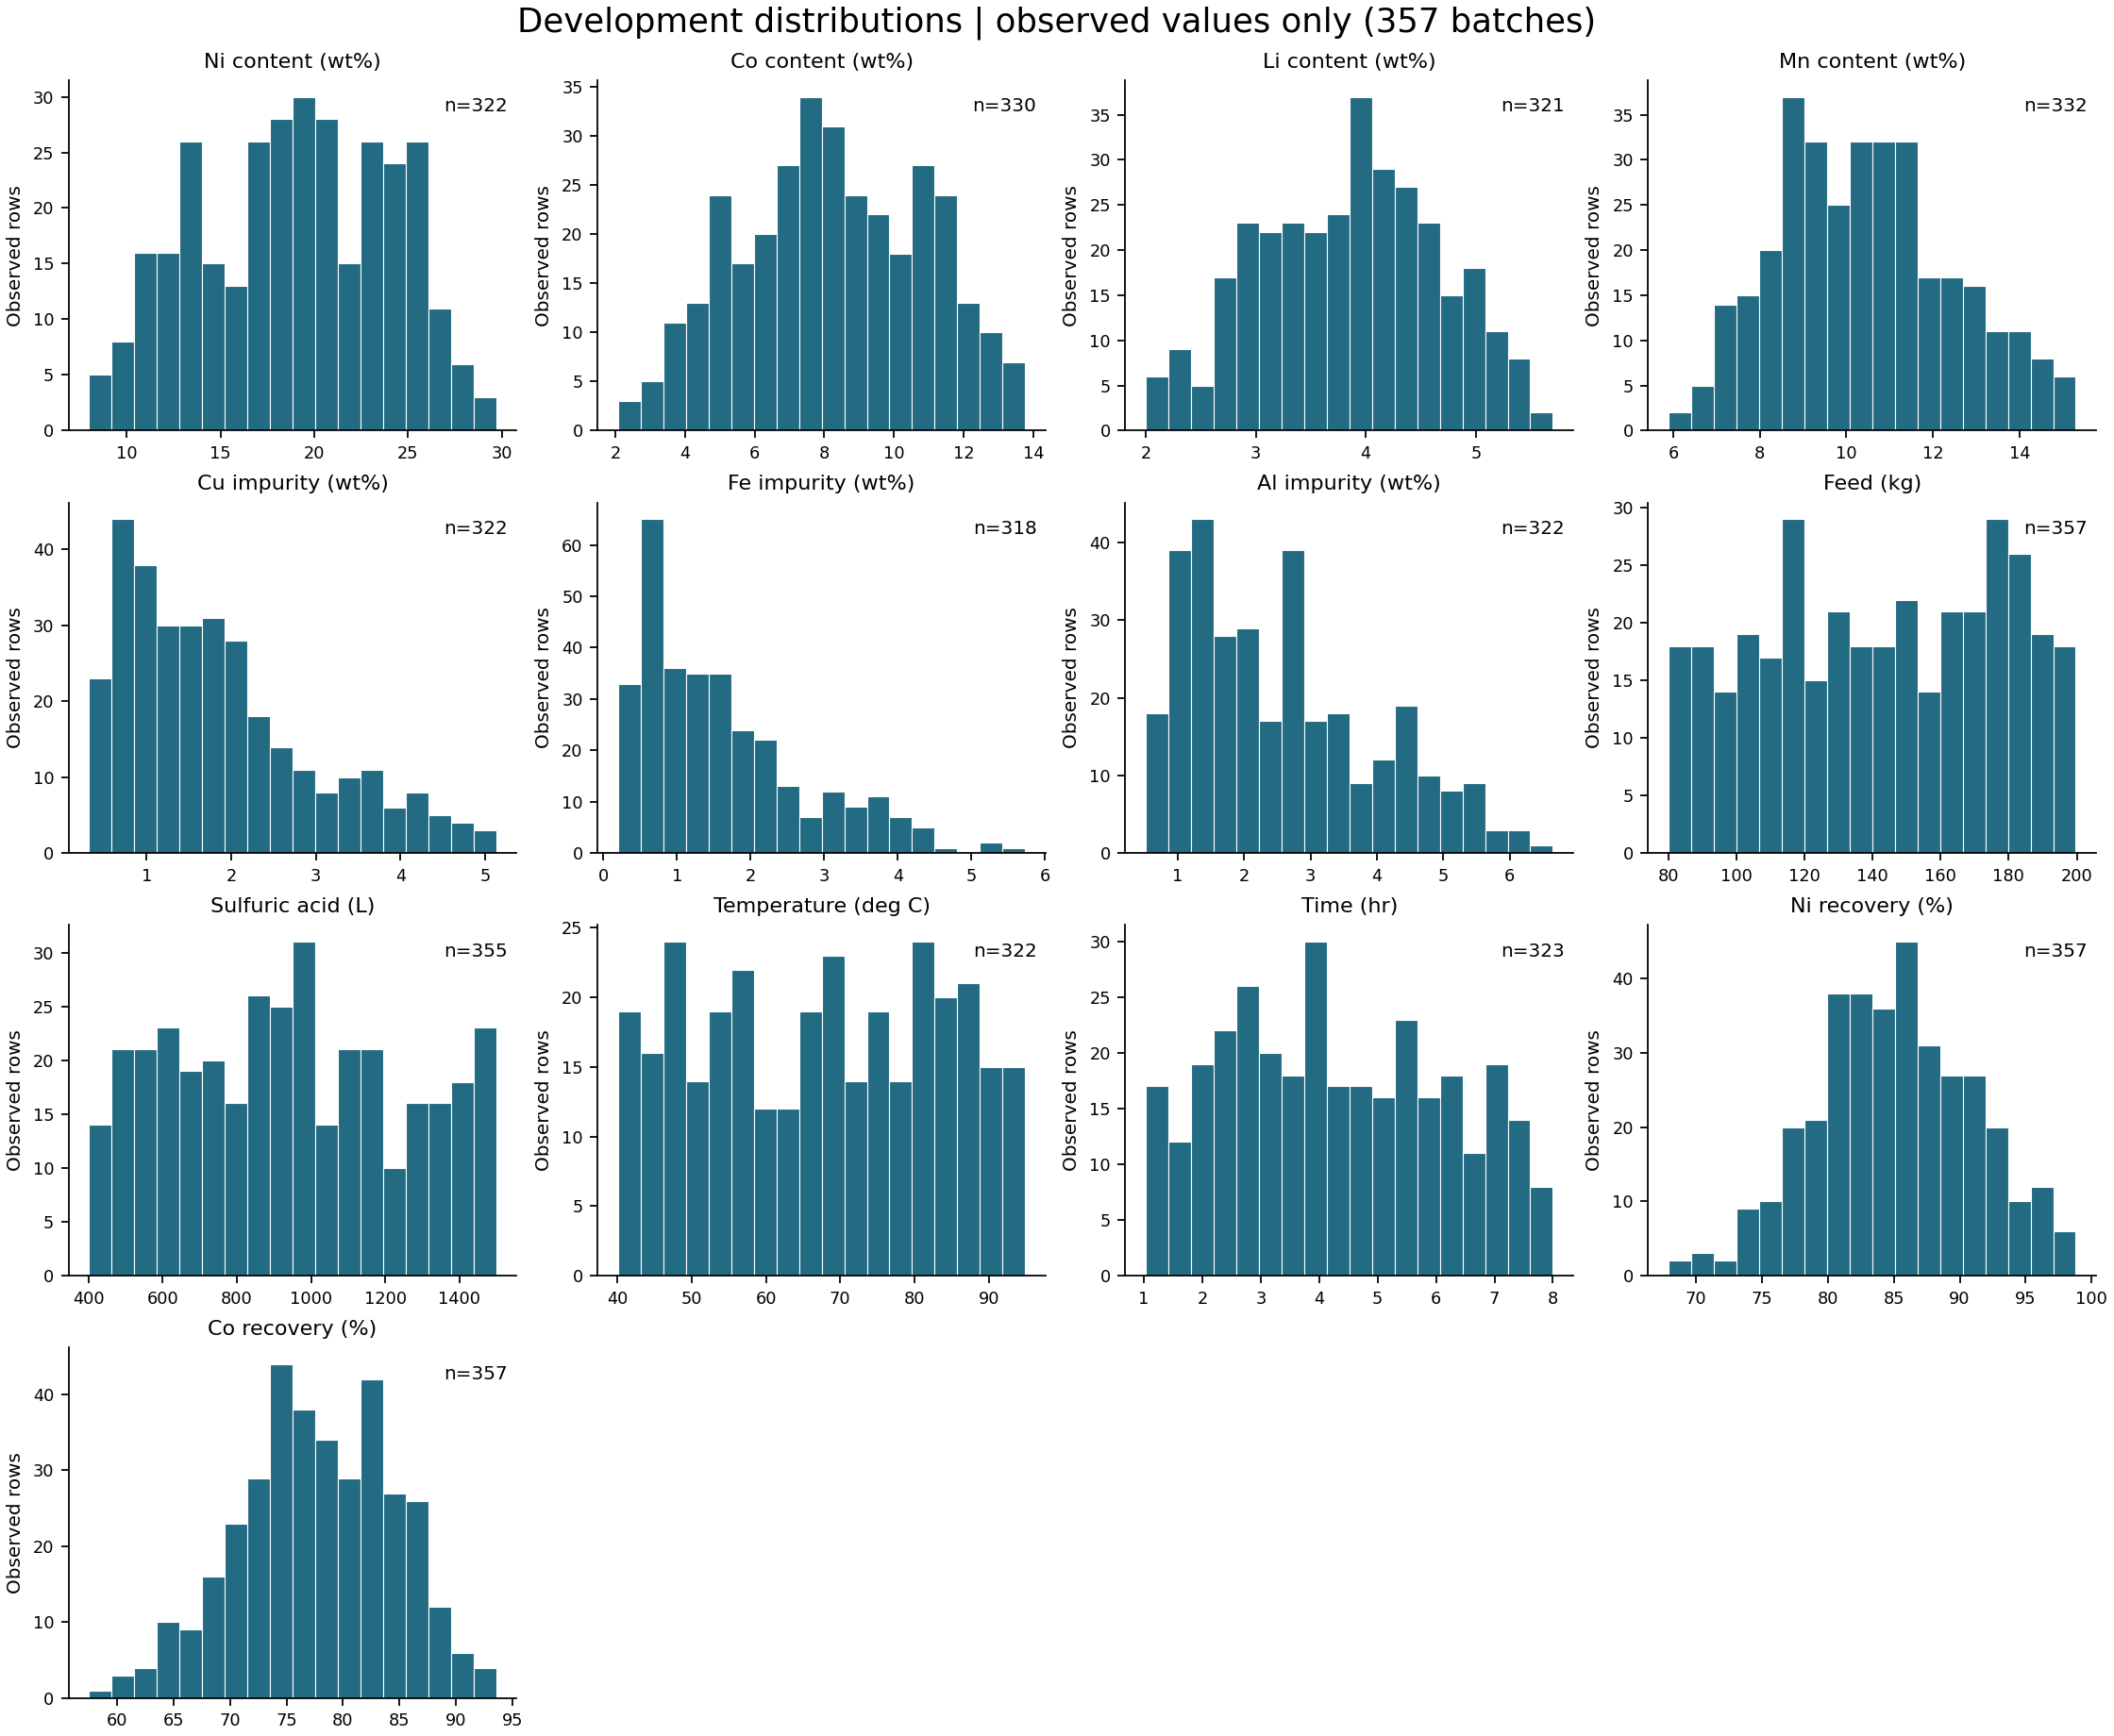

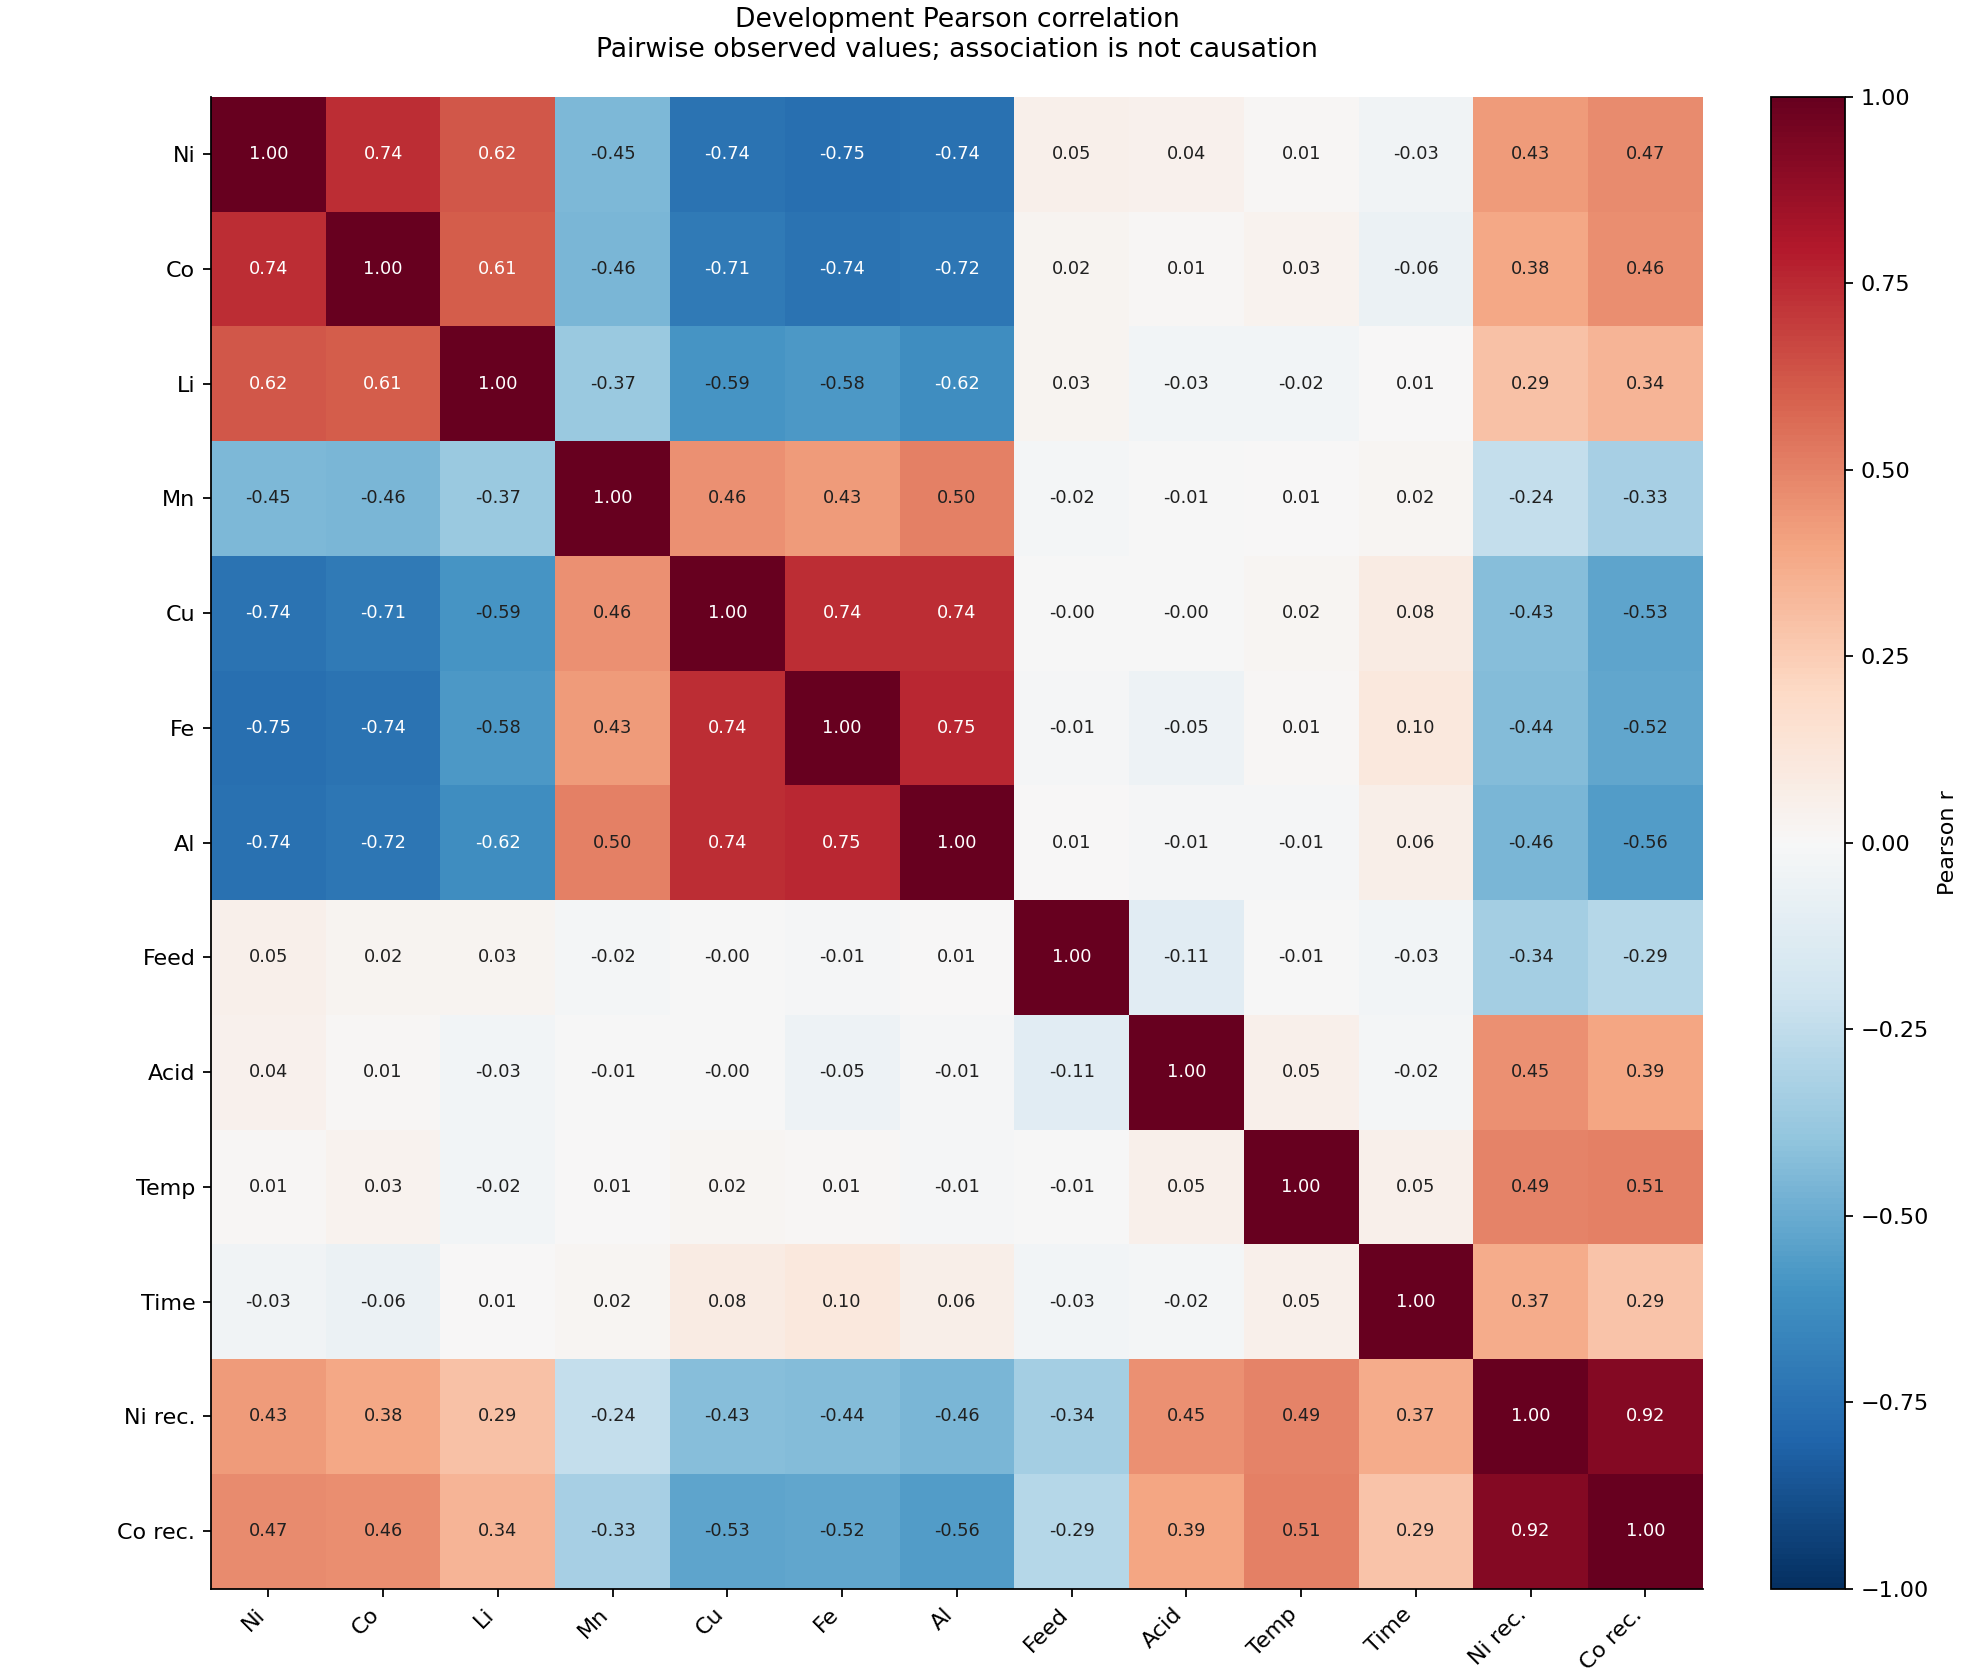

,condition,observed_development_rows
0,Ni >= 95%,21
1,Co >= 90%,9
2,Both,6


,development_rows
원료등급,
A,127
B,141
C,89


In [9]:
for name in ("development_distributions.png", "development_correlation.png"):
    display(Image(filename=str(OUT / "quality" / name)))
ni, co = TARGETS["Ni"], TARGETS["Co"]
target_support = pd.DataFrame({
    "condition": ["Ni >= 95%", "Co >= 90%", "Both"],
    "observed_development_rows": [int(dev[ni].ge(95).sum()), int(dev[co].ge(90).sum()),
                                  int((dev[ni].ge(95) & dev[co].ge(90)).sum())]})
display(target_support)
display(dev["원료등급"].value_counts().sort_index().rename("development_rows").to_frame())
print("개발 자료의 Ni-Co 상관:", dev[[ni, co]].corr().iloc[0, 1])

## 해석과 다음 단계

높은 회수율 목표를 만족하는 관측 수는 제한적입니다. 분포·상관·IQR 표는 데이터 품질과 관찰 패턴을 설명하며 인과효과나 목표 달성 보증을 제공하지 않습니다. 다음 [02_prediction.ipynb](02_prediction.ipynb)에서 같은 개발 자료의 바깥 fold 예측으로 모델을 비교합니다.

원자료의 출처와 분할 기준은 데이터 설명에, 정제 내역은 전처리 감사 기록에 있습니다. [데이터 설명](../data/README.md) · [전처리 감사 기록](../data/processed/audit.json)